# Piecewise-linear signals in the OB basis
We test whether compact linear-trend representations extend to piecewise-linear data. OB is compared with real orthonormal Fourier, DCT-II, Ternary Haar and direct piecewise-linear approximation. Neural networks and trainable activations are outside this experiment.

Mathematical properties are separated from synthetic observations. Representation budgets include index/boundary bits as well as amplitude parameters. Denoising budgets are selected on independent validation signals and then frozen for test.

## 1. Configuration, environment and code reuse
Each dimension/segment-count/alignment/continuity/profile combination contains **64 validation and 64 test** signals: 90 configurations per dimension, four dimensions. All parameters are in one cell.

Transform and error definitions are imported through AST from the previous notebook. Only explicitly listed functions/classes execute, not its experimental cells. Existing notebooks and assets are not modified during execution. MLX, NumPy, SciPy, Matplotlib, Jupyter and psutil are required; versions are recorded in metadata. Install them with `uv sync --frozen`.

In [1]:
from pathlib import Path
import ast
import csv
import hashlib
import html
import importlib.metadata
import itertools
import json
import math
import os
import platform
import subprocess
import sys
import tempfile
import time

import matplotlib.pyplot as plt
import mlx.core as mx
import nbformat
import numpy as np
import psutil
import scipy
from scipy import fft as spfft
from IPython.display import HTML, Markdown, display

CONFIG={
    "seed":42,"sizes":[81,243,729,2187],"affine_sizes":[3,9,27,81,243,729,2187],
    "segments":[2,3,4,8,16],"alignments":["ternary","arbitrary","shifted"],
    "continuities":["continuous","discontinuous"],
    "profiles":["mixed","alternating","local_short"],
    "test_samples":64,"validation_samples":64,"dtype":"float32","ob_device":"gpu","batch_size":64,
    "coefficient_counts":[4,8,16,32,64,128,256,512],"coefficient_fractions":[.01,.05,.10,.20,.40,.60,1.0],
    "pl_segment_counts":[1,2,3,4,8,16,32],"minimum_segment_length":2,
    "refine_iterations":2,"refine_radius":5,"boundary_radius":2,
    "noise_snr_db":[0,10,20],"target_relative_errors":[.01,.001],
    "fixed_bits_per_sample":12,"affine_relative_threshold":1e-12,
    "timing_batch":64,"timing_warmup":3,"timing_repeats":9,"timing_min_warmup_seconds":.15,"storage_process_repeats":3,
    "output_dir":"ob_piecewise_linear_results",
}
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'obf/core.py').exists())
sys.path.insert(0,str(ROOT))
from obf.core import OBMatrix
OUT=ROOT/CONFIG["output_dir"];OUT.mkdir(exist_ok=True)
DTYPE=np.dtype(CONFIG["dtype"])
BASIS_METHODS=["OB","Fourier","DCT-II","Ternary Haar"]
ALL_METHODS=BASIS_METHODS+["PL estimated","PL oracle"]
COLORS=dict(zip(ALL_METHODS,["#235789","#a76b00","#b24f36","#637a32","#643a91","#555555"]))
STYLES=dict(zip(ALL_METHODS,["-","--","-.",":","-","--"]))
plt.rcParams.update({"font.size":10,"axes.grid":True,"grid.alpha":.16,"axes.spines.top":False,"axes.spines.right":False})
PREVIOUS=ROOT/'ob_transform_comparison.ipynb'
prior=nbformat.read(PREVIOUS,as_version=4)
wanted={"Transform","OBTransformAdapter","fourier_forward","fourier_inverse","haar_forward","haar_inverse",
        "make_transforms","batched","select_coefficients","metrics"}
loaded=set()
for cell in prior.cells:
    if cell.cell_type!="code":continue
    for node in ast.parse(cell.source).body:
        if isinstance(node,(ast.FunctionDef,ast.ClassDef)) and node.name in wanted:
            exec(compile(ast.Module(body=[node],type_ignores=[]),str(PREVIOUS),"exec"),globals())
            loaded.add(node.name)
assert loaded==wanted,(wanted-loaded)

ENV={"python":platform.python_version(),"platform":platform.platform(),"numpy":np.__version__,
     "scipy":scipy.__version__,"mlx":importlib.metadata.version("mlx"),"hardware":mx.device_info()}
SOURCE_HASHES={str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest()
               for p in [PREVIOUS,ROOT/'obf/core.py',ROOT/'ob.py']}

def rng_for(*keys):return np.random.default_rng(np.random.SeedSequence([CONFIG['seed'],*map(int,keys)]))
def save_csv(name,rows):
    if not rows:return
    with (OUT/name).open('w',newline='') as f:
        w=csv.DictWriter(f,fieldnames=list(rows[0]));w.writeheader();w.writerows(rows)
def table(rows,columns=None,limit=25):
    if not rows:return
    columns=columns or list(rows[0])
    def fmt(v):return f"{v:.5g}" if isinstance(v,(float,np.floating)) else str(v)
    text='<table><thead><tr>'+''.join(f'<th>{html.escape(k)}</th>' for k in columns)+'</tr></thead><tbody>'
    for row in rows[:limit]:text+='<tr>'+''.join(f'<td>{html.escape(fmt(row.get(k,"")))}</td>' for k in columns)+'</tr>'
    display(HTML(text+'</tbody></table>'))
    if len(rows)>limit:print(f'Showing {limit} of {len(rows)} rows; full results are in CSV.')
def figure(fig,name):
    fig.savefig(OUT/f'{name}.png',dpi=150,bbox_inches='tight');plt.show();plt.close(fig)
def progress(stage,n=None,index=None):
    (OUT/'run_progress.json').write_text(json.dumps({"stage":stage,"n":n,"configuration_index":index,"time":time.time()}))
def asset_dir(n):
    base=ROOT/'obf/matrices'
    if n==243:
        base=ROOT/'ob_transform_comparison_results/recovered_matrices'
    path=base/f'ob_mx_{n}.safetensors'
    arrays=mx.load(str(path))
    assert all(arrays[k].shape==(n,n) for k in ['forward','inverse']),path
    return base

def coefficient_grid(n):
    return sorted(set([min(n,k) for k in CONFIG['coefficient_counts']]+[max(1,math.ceil(n*f)) for f in CONFIG['coefficient_fractions']]))
def index_bits(n):return math.ceil(math.log2(n))
def storage_budget(n,method,count):
    b=index_bits(n)
    if method in BASIS_METHODS:
        return (count,0 if count==n else count,32*count+(0 if count==n else b*count))
    continuous=method=='continuous'
    floats=count+1 if continuous else 2*count
    return floats,count-1,32*floats+b*(count-1)

ASSET_AUDIT=[]
for n in CONFIG['affine_sizes']:
    path=asset_dir(n)/f'ob_mx_{n}.safetensors';d=mx.load(str(path))
    ASSET_AUDIT.append({"n":n,"path":str(path.relative_to(ROOT)),"dtype":str(d['forward'].dtype),"bytes":path.stat().st_size,
                        "sha256":hashlib.sha256(path.read_bytes()).hexdigest()})
save_csv('asset_audit.csv',ASSET_AUDIT)
print(json.dumps(ENV,indent=2));table(ASSET_AUDIT,['n','path','dtype','bytes'])


{
  "python": "3.13.15",
  "platform": "macOS-27.2-arm64-arm-64bit-Mach-O",
  "numpy": "2.5.4",
  "scipy": "1.18.1",
  "mlx": "0.32.4",
  "hardware": {
    "device_name": "Apple M4 Max",
    "max_recommended_working_set_size": 30150672384,
    "memory_size": 38654705664,
    "architecture": "applegpu_g16s",
    "max_buffer_length": 22613000192,
    "resource_limit": 499000
  }
}


n,path,dtype,bytes
3,obf/matrices/ob_mx_3.safetensors,mlx.core.float32,226
9,obf/matrices/ob_mx_9.safetensors,mlx.core.float32,805
27,obf/matrices/ob_mx_27.safetensors,mlx.core.float32,5996
81,obf/matrices/ob_mx_81.safetensors,mlx.core.float32,52655
243,ob_transform_comparison_results/recovered_matrices/ob_mx_243.safetensors,mlx.core.int8,118268
729,obf/matrices/ob_mx_729.safetensors,mlx.core.float32,4251705
2187,obf/matrices/ob_mx_2187.safetensors,mlx.core.float32,38263936


## 2. Linear trends: algebra and numerical checks
Write the sample index using ternary digits: $i=\sum_{r=0}^{m-1}3^r d_r(i)$, where $N=3^m$ and $d_r$ is 0, 1 or 2. Synthesis row $2\cdot3^r$ equals $1-d_r(i)$; row 0 is constant 1. Therefore, for $x_i=a+bi$:

$$c_0=a+b(N-1)/2,\qquad c_{2\cdot3^r}=-b3^r,$$

and all other coefficients vanish. Here $a$ is the intercept, $b$ the slope per sample, and $c$ the coefficients of the standard OB analysis.

This derivation applies to the generator formulas, rather than extrapolating seven numerical tests. Biorthogonality follows by summing over ternary digits: independent linear forms have zero-mean factors; identical forms have mean product 1 for tables `[1,-2,1]` and `[1,-1,0]`, while opposite forms have mean product 0. Thus `forward @ inverse = N·I`.

**Conditions for K=m+1:** nonzero slope and nonzero signal mean. A nonzero constant has K=1; a centered linear trend has K=m. A centered control is included. Exact integer products for the constant and index identify algebraic zeros; float64 measures numerical residuals. All indices are zero-based.

In [2]:
AFFINE=[];AFFINE_INDICES=[]
for n in CONFIG['affine_sizes']:
    d=mx.load(str(asset_dir(n)/f'ob_mx_{n}.safetensors'))
    f=np.asarray(d['forward']).astype(np.float64);bmat=np.asarray(d['inverse']).astype(np.float64)
    m=round(math.log(n,3));positions=np.array([2*3**r for r in range(m)])
    fi=f.astype(np.int64);expected=np.zeros(n,dtype=np.int64)
    expected[0]=(n-1)//2;expected[positions]=-3**np.arange(m)
    assert np.array_equal(np.arange(n,dtype=np.int64)@fi,n*expected)
    assert np.array_equal(np.ones(n,dtype=np.int64)@fi,np.r_[n,np.zeros(n-1,dtype=np.int64)])
    for r,k in enumerate(positions):
        digits=(np.arange(n)//(3**r))%3
        assert np.array_equal(bmat[k],1-digits)
    cases={'constant':(1.25,0.),'zero_offset':(0.,1/(n-1)),'nonzero_offset':(.37,1/(n-1)),
           'negative_slope':(.25,-1/(n-1)),'centered_control':(-.5,1/(n-1))}
    for label,(offset,slope) in cases.items():
        x=offset+slope*np.arange(n);c=x@f/n
        exact=np.zeros(n);exact[0]=offset+slope*(n-1)/2;exact[positions]=-slope*3**np.arange(m)
        active=np.flatnonzero(abs(c)>max(abs(c))*CONFIG['affine_relative_threshold'])
        predicted=np.flatnonzero(abs(exact)>1e-14)
        assert np.array_equal(active,predicted),(n,label,active,predicted)
        masked=np.zeros_like(c);masked[active]=c[active]
        error=np.linalg.norm(masked@bmat-x)/np.linalg.norm(x)
        assert error<1e-11
        residual=np.max(abs(c-exact))
        AFFINE.append({'n':n,'signal':label,'significant_count':len(active),'m_plus_one':m+1,'predicted_count':len(predicted),
                       'relative_l2_float64':float(error),'max_coefficient_residual':float(residual),'active_indices':','.join(map(str,active))})
        for k in active:AFFINE_INDICES.append({'n':n,'signal':label,'index':int(k),'coefficient':float(c[k]),'formula':float(exact[k])})
    del f,bmat,fi
save_csv('affine_counts.csv',AFFINE);save_csv('affine_indices.csv',AFFINE_INDICES)
table([r for r in AFFINE if r['signal'] in ['constant','nonzero_offset','centered_control']],limit=24)


n,signal,significant_count,m_plus_one,predicted_count,relative_l2_float64,max_coefficient_residual,active_indices
3,constant,1,2,1,0,0,0
3,nonzero_offset,2,2,2,6.6698e-17,1.1102e-16,"0,2"
3,centered_control,1,2,1,0,0,2
9,constant,1,3,1,0,0,0
9,nonzero_offset,3,3,3,6.9077e-17,1.1102e-16,"0,2,6"
9,centered_control,2,3,2,0,0,"2,6"
27,constant,1,4,1,0,0,0
27,nonzero_offset,4,4,4,2.4104e-16,2.2204e-16,"0,2,6,18"
27,centered_control,3,4,3,1.5911e-16,5.5511e-17,"2,6,18"
81,constant,1,5,1,0,0,0


## 3. Piecewise-linear data generator
Boundaries are indices from 0 to N; endpoint N is unobserved. Continuous signals interpolate knot values; discontinuous signals use independent left/right values in each segment. Signals are normalized to unit RMS without mean subtraction.

Segment counts are 2, 3, 4, 8 and 16. Ternary boundaries use thirds/ninths/finer grids until enough knots exist. Arbitrary lengths vary across realizations. Shifted signals share original boundaries and parameters, but all internal boundaries receive one common feasible nonzero shift of 1–5 samples. This paired control preserves internal segment lengths; short end segments can restrict the shift below 5.

Profiles are random changes, alternating slope signs, and a short first segment with a sharp change. The ternary short-segment profile uses a finer grid. Validation and test are independent; within each split, parameters are matched across the three boundary modes.

In [3]:
CONFIGURATIONS=list(itertools.product(CONFIG['segments'],CONFIG['alignments'],CONFIG['continuities'],CONFIG['profiles']))

def generate_signals(n,segments,alignment,continuity,profile,split):
    batch=CONFIG['validation_samples'] if split=='validation' else CONFIG['test_samples']
    split_id=701 if split=='validation' else 1701
    cont_id=CONFIG['continuities'].index(continuity);profile_id=CONFIG['profiles'].index(profile)
    rows=[];bounds=[];parameters=[];shifts=[]
    minimum=CONFIG['minimum_segment_length'];m=round(math.log(n,3))
    for sample in range(batch):
        rng=rng_for(n,segments,cont_id,profile_id,split_id,sample)
        depth=math.ceil(math.log(segments,3))
        if profile=='local_short':depth=min(m-1,depth+1)
        step=n//(3**depth)
        candidates=np.arange(step,n,step)
        if profile=='local_short':
            aligned=np.r_[step,np.sort(rng.choice(candidates[candidates>step],segments-2,replace=False))]
        else:aligned=np.sort(rng.choice(candidates,segments-1,replace=False))
        # Random segment lengths respect a two-sample minimum.
        if alignment=='arbitrary':
            rr=rng_for(n,segments,cont_id,profile_id,split_id,sample,29)
            for _ in range(10000):
                interior=np.sort(rr.choice(np.arange(minimum,n-minimum+1),segments-1,replace=False))
                if profile=='local_short':
                    interior[0]=int(rr.integers(minimum,max(minimum+1,n//(4*segments)+1)))
                    interior=np.sort(interior)
                if np.min(np.diff(np.r_[0,interior,n]))>=minimum:break
            else:raise RuntimeError('Unable to sample valid random boundaries.')
            shift=0
        elif alignment=='shifted':
            allowed=[s for s in range(-5,6) if s!=0 and aligned[0]+s>=minimum and aligned[-1]+s<=n-minimum]
            assert allowed
            shift=int(rng_for(n,segments,cont_id,profile_id,split_id,sample,31).choice(allowed))
            interior=aligned+shift
        else:interior=aligned;shift=0
        knots=np.r_[0,interior,n].astype(int)
        # Parameters use a separate stream so alignment does not change them.
        rp=rng_for(n,segments,cont_id,profile_id,split_id,sample,99)
        changes=rp.normal(size=segments)
        if profile=='alternating':changes=(1-2*(np.arange(segments)%2))*rp.uniform(.5,1.5,size=segments)
        if profile=='local_short':changes[0]=rp.choice([-1,1])*rp.uniform(3,5)
        levels=rp.normal(size=segments) if continuity=='discontinuous' else np.r_[rp.normal(),np.zeros(segments-1)]
        if continuity=='continuous':levels[1:]=levels[0]+np.cumsum(changes[:-1])
        x=np.empty(n)
        for j in range(segments):
            ii=np.arange(knots[j],knots[j+1]);x[ii]=levels[j]+changes[j]*(ii-knots[j])/(knots[j+1]-knots[j])
        scale=np.sqrt(np.mean(x*x));x/=scale
        rows.append(x.astype(DTYPE));bounds.append(knots);shifts.append(shift)
        parameters.append({'levels':(levels/scale).tolist(),'changes':(changes/scale).tolist()})
    return np.stack(rows),np.stack(bounds),parameters,np.array(shifts)

def boundary_masks(knots,n):
    mask=np.zeros((len(knots),n),dtype=bool);radius=CONFIG['boundary_radius']
    for row,b in enumerate(knots):
        for k in b[1:-1]:mask[row,max(0,k-radius):min(n,k+radius+1)]=True
    return mask

x,k,p,shift=generate_signals(81,16,'shifted','continuous','local_short','test')
assert x.shape==(64,81) and np.all(np.diff(k,axis=1)>=2) and np.all(abs(shift)>=1)
print(f'Configurations per dimension: {len(CONFIGURATIONS)}; samples per split/configuration: {len(x)}')


Configurations per dimension: 90; samples per split/configuration: 64


## 4. Direct piecewise-linear fitting and storage budgets
**Oracle** knows true boundaries but estimates amplitudes only from observed values. Smaller budgets use a predetermined subset of true knots. **Estimated** receives no true boundaries: greedy binary segmentation chooses splits by observed linear-regression error reduction. This is a heuristic, not globally optimal segmentation. Every greedy path reaches the same maximum of 32 segments, retaining enough split capacity with at least two samples per segment. The oracle subset is not optimized; under insufficient budgets it is not an error lower bound and can lose to estimated fitting. Near-exact oracle recovery applies to the complete true knot set.

Continuous fits use global least squares for knot values. Up to two refinements move boundaries toward intersections of neighboring regression lines within ±5 samples, accepting only reductions in **observed** error. Discontinuous segments are fitted independently. Both modes know the continuity type; identifying that type is not studied.

For M segments, continuous storage has M+1 float32 knot values; discontinuous storage has 2M float32 line parameters. Both store M−1 boundaries at `ceil(log₂ N)` bits each. Basis storage has K float32 values and K indices, except dense K=N with implicit ordering. Headers, method identifiers, entropy coding and actual packing are omitted. This is a transparent bit estimate, not a working compressor size. PL fitting uses float64, then rounds stored parameters to float32.

In [4]:
def regression_prefix(y):
    yy=y.astype(np.float64);xx=np.arange(y.shape[1],dtype=np.float64)
    return tuple(np.pad(np.cumsum(v,axis=1),((0,0),(1,0))) for v in [yy,yy*yy,yy*xx])

def interval_parameters(prefix,left,right):
    py,pyy,pxy=prefix;rows=np.arange(len(left))[:,None]
    sy=py[rows,right]-py[rows,left];sxy=pxy[rows,right]-pxy[rows,left]
    length=right-left;meanx=(left+right-1)/2
    variance=length*(length*length-1)/12
    slope=(sxy-meanx*sy)/np.maximum(variance,1e-30)
    start=sy/length+slope*(left-meanx)
    return start,slope

def greedy_boundaries(y,max_segments):
    batch,n=y.shape;prefix=regression_prefix(y);py,pyy,pxy=prefix
    candidates=np.arange(1,n,dtype=int)[None,:];row=np.arange(batch)
    minimum=CONFIG['minimum_segment_length']
    capacity=np.full(batch,n//minimum,dtype=int)
    def sse(left,right):
        length=right-left
        sy=py[row,right]-py[row,left];ss=pyy[row,right]-pyy[row,left];sxy=pxy[row,right]-pxy[row,left]
        meanx=(left+right-1)/2;var=length*(length*length-1)/12
        return np.maximum(0,ss-sy*sy/length-(sxy-meanx*sy)**2/np.maximum(var,1e-30))
    def best(left,right):
        l=left[:,None];r=right[:,None]
        ll=candidates-l;lr=r-candidates
        sl=py[:,1:n]-py[row,left,None];sr=py[row,right,None]-py[:,1:n]
        sql=pyy[:,1:n]-pyy[row,left,None];sqr=pyy[row,right,None]-pyy[:,1:n]
        xyl=pxy[:,1:n]-pxy[row,left,None];xyr=pxy[row,right,None]-pxy[:,1:n]
        vl=ll*(ll*ll-1)/12;vr=lr*(lr*lr-1)/12
        el=sql-sl*sl/np.maximum(ll,1)-(xyl-(l+candidates-1)/2*sl)**2/np.maximum(vl,1e-30)
        er=sqr-sr*sr/np.maximum(lr,1)-(xyr-(candidates+r-1)/2*sr)**2/np.maximum(vr,1e-30)
        gain=sse(left,right)[:,None]-np.maximum(0,el)-np.maximum(0,er)
        remaining_capacity=capacity[:,None]-(r-l)//minimum+ll//minimum+lr//minimum
        gain=np.where((ll>=minimum)&(lr>=minimum)&(remaining_capacity>=max_segments),gain,-np.inf)
        ix=np.argmax(gain,axis=1)
        return candidates[0,ix],gain[row,ix]
    starts=np.zeros((batch,max_segments),dtype=int);ends=np.zeros_like(starts)
    cuts=np.zeros_like(starts);gains=np.full((batch,max_segments),-np.inf)
    ends[:,0]=n;cuts[:,0],gains[:,0]=best(starts[:,0],ends[:,0])
    selected=np.empty((batch,max_segments-1),dtype=int)
    paths={1:np.empty((batch,0),dtype=int)}
    for current in range(1,max_segments):
        which=np.argmax(gains[:,:current],axis=1)
        split=cuts[row,which];old_right=ends[row,which]
        assert np.all(np.isfinite(gains[row,which]))
        selected[:,current-1]=split
        old_capacity=capacity.copy()
        old_left=starts[row,which].copy()
        capacity-=(old_right-old_left)//minimum-(split-old_left)//minimum-(old_right-split)//minimum
        ends[row,which]=split
        cuts[row,which],gains[row,which]=best(starts[row,which],split)
        starts[:,current]=split;ends[:,current]=old_right
        cuts[:,current],gains[:,current]=best(split,old_right)
        if np.any((old_capacity>max_segments)&(capacity==max_segments)):
            for slot in range(current+1):cuts[:,slot],gains[:,slot]=best(starts[:,slot],ends[:,slot])
        if current+1 in CONFIG['pl_segment_counts']:paths[current+1]=np.sort(selected[:,:current],axis=1).copy()
    return paths,prefix

def interval_labels(knots,n):
    xx=np.arange(n)
    return np.stack([np.searchsorted(row[1:-1],xx,side='right') for row in knots])

def fit_piecewise(y,knots,continuity,prefix=None):
    batch,n=y.shape;m=knots.shape[1]-1
    labels=interval_labels(knots,n);rows=np.arange(batch)[:,None];xx=np.arange(n)[None,:]
    left=np.take_along_axis(knots,labels,axis=1);right=np.take_along_axis(knots,labels+1,axis=1)
    weight=(xx-left)/(right-left)
    if continuity=='discontinuous':
        prefix=regression_prefix(y) if prefix is None else prefix
        a,b=interval_parameters(prefix,knots[:,:-1],knots[:,1:])
        first=a.astype(DTYPE);last=(a+b*np.diff(knots,axis=1)).astype(DTYPE)
        return ((1-weight)*np.take_along_axis(first,labels,axis=1)+weight*np.take_along_axis(last,labels,axis=1)).astype(DTYPE)
    q=m+1;left_index=(np.arange(batch)[:,None]*q+labels).ravel();right_index=left_index+1
    wl=1-weight;wr=weight
    diag=(np.bincount(left_index,weights=(wl*wl).ravel(),minlength=batch*q)+np.bincount(right_index,weights=(wr*wr).ravel(),minlength=batch*q)).reshape(batch,q)
    rhs=(np.bincount(left_index,weights=(wl*y).ravel(),minlength=batch*q)+np.bincount(right_index,weights=(wr*y).ravel(),minlength=batch*q)).reshape(batch,q)
    off_index=(np.arange(batch)[:,None]*m+labels).ravel()
    off=np.bincount(off_index,weights=(wl*wr).ravel(),minlength=batch*m).reshape(batch,m)
    for j in range(1,q):
        factor=off[:,j-1]/diag[:,j-1];diag[:,j]-=factor*off[:,j-1];rhs[:,j]-=factor*rhs[:,j-1]
    solution=np.empty_like(rhs);solution[:,-1]=rhs[:,-1]/diag[:,-1]
    for j in range(q-2,-1,-1):solution[:,j]=(rhs[:,j]-off[:,j]*solution[:,j+1])/diag[:,j]
    solution=solution.astype(DTYPE)
    return (wl*np.take_along_axis(solution,labels,axis=1)+wr*np.take_along_axis(solution,labels+1,axis=1)).astype(DTYPE)

def refine_continuous(y,knots,prefix):
    original=knots.copy();fitted=fit_piecewise(y,original,'continuous',prefix)
    error=np.sum((fitted.astype(np.float64)-y)**2,axis=1)
    for _ in range(CONFIG['refine_iterations']):
        a,b=interval_parameters(prefix,original[:,:-1],original[:,1:])
        intercept=a-b*original[:,:-1]
        denominator=b[:,:-1]-b[:,1:]
        crossing=np.divide(intercept[:,1:]-intercept[:,:-1],denominator,out=original[:,1:-1].astype(float).copy(),where=abs(denominator)>1e-12)
        candidate=original.copy();radius=CONFIG['refine_radius'];minimum=CONFIG['minimum_segment_length']
        for j in range(1,knots.shape[1]-1):
            low=np.maximum(candidate[:,j-1]+minimum,original[:,j]-radius)
            high=np.minimum(original[:,j+1]-minimum,original[:,j]+radius)
            candidate[:,j]=np.clip(np.rint(crossing[:,j-1]),low,high).astype(int)
        predicted=fit_piecewise(y,candidate,'continuous',prefix)
        candidate_error=np.sum((predicted.astype(np.float64)-y)**2,axis=1)
        accepted=candidate_error<error
        original[accepted]=candidate[accepted];fitted[accepted]=predicted[accepted];error[accepted]=candidate_error[accepted]
    return original,fitted

def piecewise_path(y,true_knots,continuity,estimated_counts=None):
    n=y.shape[1];counts=CONFIG['pl_segment_counts'] if estimated_counts is None else estimated_counts
    max_segments=min(max(CONFIG['pl_segment_counts']),n//CONFIG['minimum_segment_length'])
    paths,prefix=greedy_boundaries(y,max_segments)
    estimated={}
    for m in counts:
        if m>max_segments:continue
        knots=np.column_stack((np.zeros(len(y),int),paths[m],np.full(len(y),n)))
        if continuity=='continuous':knots,predicted=refine_continuous(y,knots,prefix)
        else:predicted=fit_piecewise(y,knots,continuity,prefix)
        estimated[m]=(predicted,knots)
    total=true_knots.shape[1]-1;oracle={}
    for requested in counts:
        m=min(requested,total)
        if m in oracle:continue
        indices=np.rint(np.linspace(0,total,m+1)).astype(int)
        knots=true_knots[:,indices]
        oracle[m]=(fit_piecewise(y,knots,continuity,prefix),knots)
    return estimated,oracle

# Local correctness checks use generated observations rather than reference outputs.
for continuity in CONFIG['continuities']:
    for segments in [2,3,16]:
        yy,kk,_,_=generate_signals(81,segments,'arbitrary',continuity,'alternating','test')
        predicted=fit_piecewise(yy,kk,continuity)
        assert np.max(np.linalg.norm(predicted-yy,axis=1)/np.linalg.norm(yy,axis=1))<2e-6
        paths,_=greedy_boundaries(yy,32)
        assert all(np.all(np.diff(np.column_stack((np.zeros(64,int),v,np.full(64,81))),axis=1)>=2) for v in paths.values())
# Check continuous fitting against an explicit dense design matrix.
y=rng_for(81,9901).normal(size=(4,81)).astype(DTYPE)
knots=np.tile(np.array([0,9,27,54,81]),(4,1))
predicted=fit_piecewise(y,knots,'continuous')
labels=interval_labels(knots,81)
for row in range(4):
    design=np.zeros((81,5));ii=np.arange(81);segment=labels[row]
    weight=(ii-knots[row,segment])/(knots[row,segment+1]-knots[row,segment])
    design[ii,segment]=1-weight;design[ii,segment+1]=weight
    fitted=np.linalg.lstsq(design,y[row].astype(float),rcond=None)[0].astype(DTYPE)
    reference=(design@fitted).astype(DTYPE)
    assert np.max(abs(reference-predicted[row]))<1e-6
assert storage_budget(81,'continuous',16)==(17,15,649)
assert storage_budget(81,'discontinuous',16)==(32,15,1129)
print('Oracle fits, dense least-squares agreement, budget accounting and segment-ordering checks passed.')


Oracle fits, dense least-squares agreement, budget accounting and segment-ordering checks passed.


## 5. Method validation and sparse reconstruction
OB ranking follows the previous experiment: `abs(c[j])·||inverse[j,:]||₂`. This is not globally optimal biorthogonal K-term approximation. Quality is measured after reconstruction in signal space.

Each test signal has relative L2, RMSE and boundary RMSE within ±2 samples of true boundaries. Curves record actual float parameters, indices and bits. The first **tested** grid budget reaching 1% or 0.1% relative error is reported, together with the fraction failing to reach each target. This is neither exact minimum K nor optimal-mask search.

The main slice uses a common limit of 12 bits per input sample and the largest available code within it. Realizations and configurations receive equal weights; favorable signals are not selected.

In [5]:
VALIDATION=[];MODELS={}
for n in CONFIG['sizes']:
    transforms=make_transforms(n,asset_dir(n))
    x=rng_for(n,8101).normal(size=(16,n)).astype(DTYPE)
    for name,t in transforms.items():
        c=t.forward(x);restored=t.inverse(select_coefficients(c,t,n))
        relative=np.linalg.norm(restored-x,axis=1)/np.linalg.norm(x,axis=1)
        assert c.shape==x.shape and c.dtype==DTYPE and np.isrealobj(c)
        assert max(relative)<3e-5
        order=np.argsort(-np.abs(c)*t.synthesis_norms,axis=1,kind='stable');masked=np.zeros_like(c)
        selected=order[:,:4];np.put_along_axis(masked,selected,np.take_along_axis(c,selected,axis=1),axis=1)
        assert np.array_equal(masked,select_coefficients(c,t,4))
        if name!='OB':assert np.max(abs(np.sum(c.astype(float)**2,axis=1)/np.sum(x.astype(float)**2,axis=1)-1))<5e-6
        VALIDATION.append({'n':n,'method':name,'max_roundtrip_relative':float(max(relative)),'status':'passed'})
    MODELS[n]=transforms
save_csv('transform_validation.csv',VALIDATION);table(VALIDATION,limit=20)

def configuration_meta(n,cfg):
    s,a,c,p=cfg
    return {'n':n,'segments':s,'alignment':a,'continuity':c,'profile':p}

def result_record(meta,method,candidate,actual,values):
    if method in BASIS_METHODS:floats,integers,bits=storage_budget(meta['n'],method,actual)
    else:floats,integers,bits=storage_budget(meta['n'],meta['continuity'],actual)
    row={**meta,'method':method,'candidate':int(candidate),'actual_components':int(actual),'float_params':int(floats),
         'index_params':int(integers),'total_params':int(floats+integers),'storage_bits':int(bits),'count':len(values['relative_l2'])}
    for key in ['relative_l2','rmse','boundary_rmse','max_abs']:
        if key not in values:continue
        row[key+'_mean']=float(np.mean(values[key]));row[key+'_std']=float(np.std(values[key],ddof=1))
    return row

def evaluate_observation(clean,observed,knots,continuity,models,counts=None):
    n=clean.shape[1];mask=boundary_masks(knots,n)
    for name,t in models.items():
        c=batched(t.forward,observed)
        candidates=coefficient_grid(n) if counts is None else [counts[name]]
        order=np.argsort(-np.abs(c)*t.synthesis_norms,axis=1,kind='stable')
        for k in candidates:
            retained=np.zeros_like(c);selected=order[:,:k]
            np.put_along_axis(retained,selected,np.take_along_axis(c,selected,axis=1),axis=1)
            predicted=batched(t.inverse,retained)
            yield name,k,k,predicted,metrics(clean,predicted,mask)
    desired=CONFIG['pl_segment_counts'] if counts is None else sorted(set([counts['PL estimated'],counts['PL oracle']]))
    estimated,oracle=piecewise_path(observed,knots,continuity,desired)
    for method,path in [('PL estimated',estimated),('PL oracle',oracle)]:
        candidates=CONFIG['pl_segment_counts'] if counts is None else [counts[method]]
        for requested in candidates:
            actual=min(requested,knots.shape[1]-1) if method=='PL oracle' else requested
            if actual not in path:continue
            predicted,_=path[actual]
            yield method,requested,actual,predicted,metrics(clean,predicted,mask)

def noise_observation(clean,n,cfg,snr,split):
    s,a,c,p=cfg
    rng=rng_for(n,s,CONFIG['alignments'].index(a),CONFIG['continuities'].index(c),CONFIG['profiles'].index(p),snr,9801 if split=='validation' else 19801)
    noise=rng.normal(size=clean.shape)*np.sqrt(np.mean(clean.astype(float)**2,axis=1,keepdims=True))*10**(-snr/20)
    return (clean+noise).astype(DTYPE)

def pooled(rows,metric='relative_l2'):
    total=sum(r['count'] for r in rows)
    mean=sum(r['count']*r[metric+'_mean'] for r in rows)/total
    variance=sum((r['count']-1)*r[metric+'_std']**2+r['count']*(r[metric+'_mean']-mean)**2 for r in rows)/max(1,total-1)
    return float(mean),float(np.sqrt(variance))

# Keep only compact statistics. The full datasets remain reproducible from seeds.
SPARSE=[];NEEDED=[];VALIDATION_NOISE=[];TEST_NOISE=[];NOISE_BASELINE=[];CHOICES=[];EXAMPLES=[];GENERATION_AUDIT=[]
START=time.perf_counter()
for n in CONFIG['sizes']:
    models=MODELS[n]
    for ci,cfg in enumerate(CONFIGURATIONS):
        progress('clean_and_validation',n,ci)
        meta=configuration_meta(n,cfg);s,alignment,continuity,profile=cfg
        clean,knots,params,shifts=generate_signals(n,*cfg,'test')
        GENERATION_AUDIT.append({**meta,'split':'test','samples':len(clean),'min_segment_length':int(np.diff(knots,axis=1).min()),
                                 'abs_shift_min':int(abs(shifts).min()),'abs_shift_max':int(abs(shifts).max())})
        needed={method:{tol:np.full(len(clean),np.nan) for tol in CONFIG['target_relative_errors']} for method in ALL_METHODS}
        needed_counts={method:{tol:np.full(len(clean),np.nan) for tol in CONFIG['target_relative_errors']} for method in ALL_METHODS}
        for method,candidate,actual,predicted,values in evaluate_observation(clean,clean,knots,continuity,models):
            record=result_record(meta,method,candidate,actual,values);SPARSE.append(record)
            if method in BASIS_METHODS and actual==n:assert np.max(values['relative_l2'])<3e-5
            for tol in CONFIG['target_relative_errors']:
                target=needed[method][tol];passing=(values['relative_l2']<=tol)&np.isnan(target)
                target[passing]=record['storage_bits'];needed_counts[method][tol][passing]=actual
        for method,thresholds in needed.items():
            for tol,values in thresholds.items():
                finite=np.isfinite(values)
                NEEDED.append({**meta,'method':method,'target_relative_error':tol,'reached_fraction':float(finite.mean()),
                               'first_grid_bits_mean_reached':float(values[finite].mean()) if finite.any() else float('nan'),
                               'first_grid_components_mean_reached':float(needed_counts[method][tol][finite].mean()) if finite.any() else float('nan'),
                               'first_grid_bits_std_reached':float(values[finite].std(ddof=1)) if finite.sum()>1 else 0.})
        if n==729 and s in [3,8] and profile=='alternating' and alignment in ['ternary','shifted']:
            EXAMPLES.append({**meta,'sample':0,'knots':knots[0].tolist(),'parameters':params[0],'shift':int(shifts[0])})
        validation,vknots,_,_=generate_signals(n,*cfg,'validation')
        for snr in CONFIG['noise_snr_db']:
            observed=noise_observation(validation,n,cfg,snr,'validation')
            vmeta={**meta,'snr_db':snr,'split':'validation'}
            for method,candidate,actual,predicted,values in evaluate_observation(validation,observed,vknots,continuity,models):
                VALIDATION_NOISE.append(result_record(vmeta,method,candidate,actual,values))
        if (ci+1)%30==0:print(f'N={n}: completed clean/validation configuration {ci+1}/{len(CONFIGURATIONS)}')
    # Freeze one candidate per N, SNR, continuity and method. No segment-count or alignment conditioning.
    choices={}
    for continuity,snr,method in itertools.product(CONFIG['continuities'],CONFIG['noise_snr_db'],ALL_METHODS):
        rows=[r for r in VALIDATION_NOISE if r['n']==n and r['continuity']==continuity and r['snr_db']==snr and r['method']==method]
        candidates=sorted(set(r['candidate'] for r in rows));scores=[]
        for candidate in candidates:
            group=[r for r in rows if r['candidate']==candidate]
            assert len(group)==len(CONFIGURATIONS)//2
            error,sd=pooled(group);bits=np.mean([r['storage_bits'] for r in group])
            scores.append((error,bits,candidate,sd))
        error,bits,candidate,sd=min(scores)
        choices[(continuity,snr,method)]=candidate
        CHOICES.append({'n':n,'continuity':continuity,'snr_db':snr,'method':method,'selected_candidate':candidate,
                        'validation_error_mean':error,'validation_error_std':sd,'validation_mean_bits':float(bits),
                        'validation_signals':len(group)*CONFIG['validation_samples']})
    for ci,cfg in enumerate(CONFIGURATIONS):
        progress('frozen_test_noise',n,ci)
        clean,knots,_,_=generate_signals(n,*cfg,'test');meta=configuration_meta(n,cfg);continuity=cfg[2]
        for snr in CONFIG['noise_snr_db']:
            observed=noise_observation(clean,n,cfg,snr,'test');nmeta={**meta,'snr_db':snr,'split':'test'}
            baseline=metrics(clean,observed,boundary_masks(knots,n))
            base=result_record(nmeta,'Unfiltered',n,n,baseline)
            base.update({'float_params':n,'index_params':0,'total_params':n,'storage_bits':32*n,
                         'realized_snr_db_mean':float(np.mean(-20*np.log10(baseline['relative_l2']))),
                         'realized_snr_db_std':float(np.std(-20*np.log10(baseline['relative_l2']),ddof=1))})
            NOISE_BASELINE.append(base)
            selected={method:choices[(continuity,snr,method)] for method in ALL_METHODS}
            for method,candidate,actual,predicted,values in evaluate_observation(clean,observed,knots,continuity,models,selected):
                record=result_record(nmeta,method,candidate,actual,values)
                improvement=baseline['relative_l2']-values['relative_l2']
                record.update({'paired_improvement_mean':float(improvement.mean()),'paired_improvement_std':float(improvement.std(ddof=1)),
                               'fraction_signals_improved':float(np.mean(improvement>0))})
                TEST_NOISE.append(record)
        if (ci+1)%30==0:print(f'N={n}: completed frozen test-noise configuration {ci+1}/{len(CONFIGURATIONS)}')
    save_csv('sparse_reconstruction.csv',SPARSE);save_csv('first_grid_budgets.csv',NEEDED)
    save_csv('noise_validation_curves.csv',VALIDATION_NOISE);save_csv('noise_budget_choices.csv',CHOICES)
    save_csv('noise_test_selected.csv',TEST_NOISE);save_csv('noise_test_unfiltered.csv',NOISE_BASELINE)
    save_csv('generation_audit.csv',GENERATION_AUDIT)
    print(f'Completed N={n}; elapsed {time.perf_counter()-START:.1f} seconds.')
(OUT/'example_parameters.json').write_text(json.dumps(EXAMPLES,indent=2))
progress('statistical_benchmarks_complete')


n,method,max_roundtrip_relative,status
81,OB,2.6289e-07,passed
81,Fourier,1.9575e-07,passed
81,DCT-II,1.7908e-07,passed
81,Ternary Haar,7.406e-08,passed
243,OB,3.5354e-07,passed
243,Fourier,2.2727e-07,passed
243,DCT-II,2.0383e-07,passed
243,Ternary Haar,6.3532e-08,passed
729,OB,5.5284e-07,passed
729,Fourier,2.0155e-07,passed


N=81: completed clean/validation configuration 30/90


N=81: completed clean/validation configuration 60/90


N=81: completed clean/validation configuration 90/90


N=81: completed frozen test-noise configuration 30/90


...

N=2187: completed clean/validation configuration 90/90


N=2187: completed frozen test-noise configuration 30/90


N=2187: completed frozen test-noise configuration 60/90


N=2187: completed frozen test-noise configuration 90/90


Completed N=2187; elapsed 257.8 seconds.


## 6. Error curves, budget growth and boundary shifts
The common plot axis is **representation bits**, including float32 parameters and indices. Tables show standard deviations across realizations; curve lines are means. Separate views show boundary modes, continuity and segment counts. Oracle controls attainable accuracy with known knots.

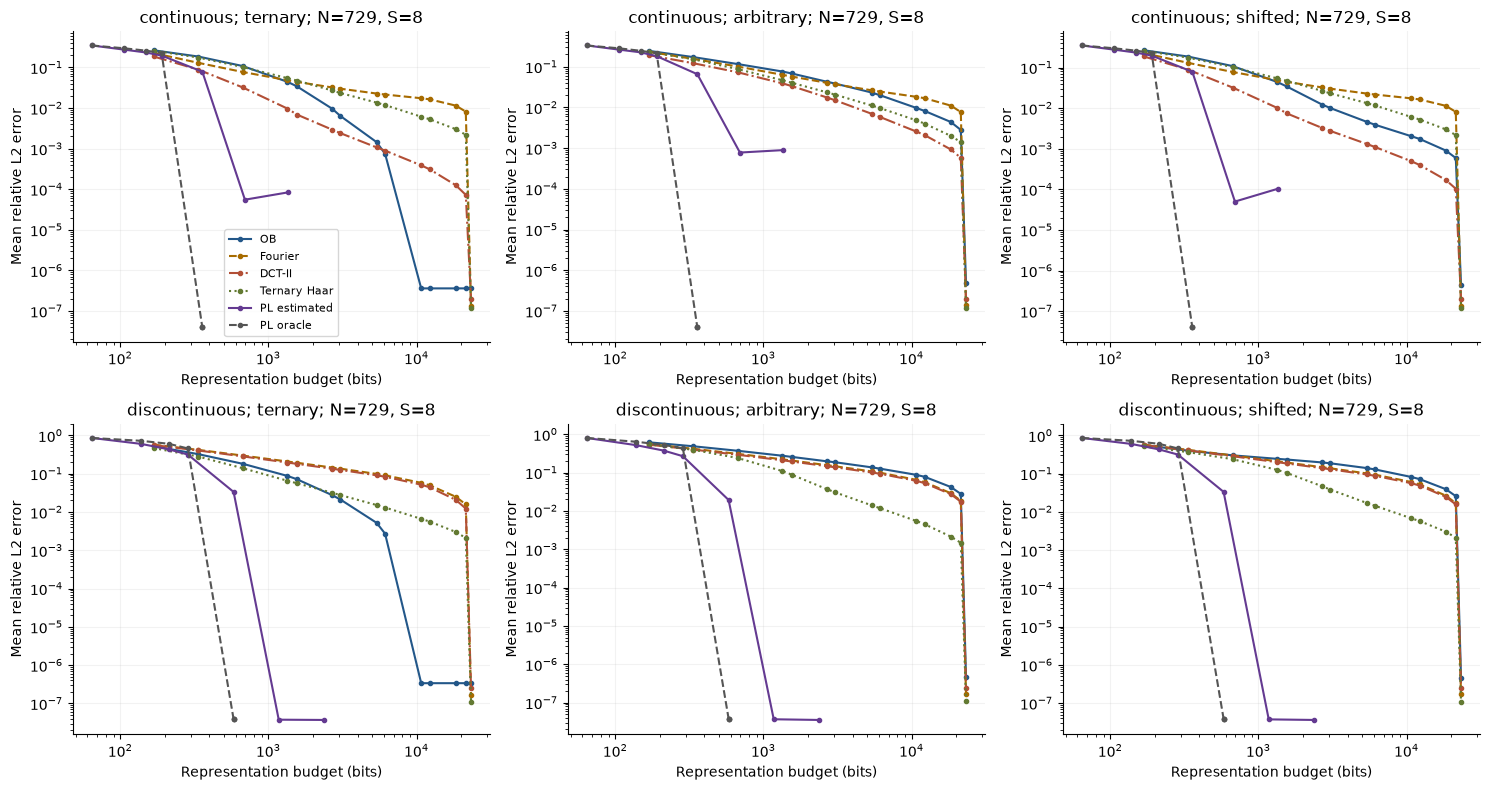

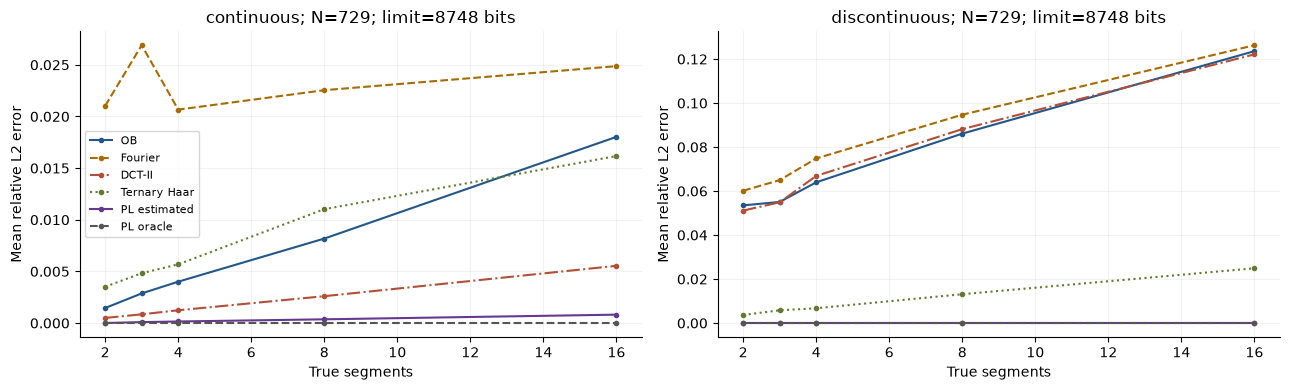

n,continuity,alignment,method,mean_relative_l2,std_relative_l2,mean_boundary_rmse,std_boundary_rmse,mean_bits
729,continuous,ternary,OB,0.0022597,0.0059872,0.0029434,0.0085301,6132
729,continuous,ternary,Fourier,0.02246,0.015779,0.0084193,0.0067876,6132
729,continuous,ternary,DCT-II,0.00097265,0.0013204,0.0028302,0.0026518,6132
729,continuous,ternary,Ternary Haar,0.0087109,0.010745,0.0094327,0.011481,6132
729,continuous,ternary,PL estimated,0.00011885,0.00040307,0.00045407,0.0013765,1366
729,continuous,ternary,PL oracle,3.9721e-08,8.8323e-09,3.7092e-08,2.0313e-08,299.2
729,continuous,arbitrary,OB,0.013941,0.016027,0.033942,0.041531,6132
729,continuous,arbitrary,Fourier,0.024596,0.017573,0.019298,0.027893,6132
729,continuous,arbitrary,DCT-II,0.0042553,0.0070627,0.013904,0.025137,6132
729,continuous,arbitrary,Ternary Haar,0.0074699,0.0094076,0.0080405,0.010751,6132


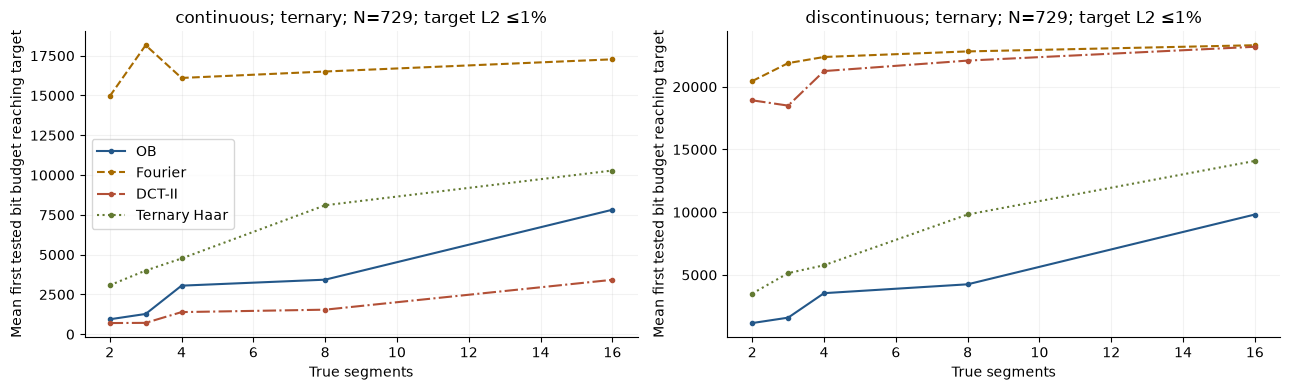

In [6]:
FIXED=[]
for n,cfg in itertools.product(CONFIG['sizes'],CONFIGURATIONS):
    meta=configuration_meta(n,cfg);limit=CONFIG['fixed_bits_per_sample']*n
    for method in ALL_METHODS:
        rows=[r for r in SPARSE if all(r[k]==v for k,v in meta.items()) and r['method']==method and r['storage_bits']<=limit]
        if not rows:continue
        selected=max(rows,key=lambda r:(r['storage_bits'],r['candidate']))
        FIXED.append({**selected,'budget_limit_bits':limit})
save_csv('fixed_bit_budget.csv',FIXED)

n=729
fig,axes=plt.subplots(2,3,figsize=(15,8))
for row,continuity in enumerate(CONFIG['continuities']):
    for col,alignment in enumerate(CONFIG['alignments']):
        ax=axes[row,col]
        for method in ALL_METHODS:
            rows=[r for r in SPARSE if r['n']==n and r['segments']==8 and r['continuity']==continuity and r['alignment']==alignment and r['method']==method]
            candidates=sorted(set(r['candidate'] for r in rows));bits=[];errors=[]
            for candidate in candidates:
                group=[r for r in rows if r['candidate']==candidate]
                bits.append(np.mean([r['storage_bits'] for r in group]));errors.append(pooled(group)[0])
            order=np.argsort(bits)
            ax.loglog(np.array(bits)[order],np.maximum(np.array(errors)[order],1e-8),label=method,color=COLORS[method],ls=STYLES[method],marker='.')
        ax.set(title=f'{continuity}; {alignment}; N={n}, S=8',xlabel='Representation budget (bits)',ylabel='Mean relative L2 error')
axes[0,0].legend(fontsize=8);fig.tight_layout();figure(fig,'error_vs_bit_budget')

fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,continuity in zip(axes,CONFIG['continuities']):
    for method in ALL_METHODS:
        yy=[];sd=[]
        for segments in CONFIG['segments']:
            rows=[r for r in FIXED if r['n']==n and r['segments']==segments and r['continuity']==continuity and r['method']==method]
            mean,spread=pooled(rows);yy.append(mean);sd.append(spread)
        ax.plot(CONFIG['segments'],yy,label=method,color=COLORS[method],ls=STYLES[method],marker='.')
    ax.set(title=f'{continuity}; N={n}; limit={CONFIG["fixed_bits_per_sample"]*n} bits',xlabel='True segments',ylabel='Mean relative L2 error')
axes[0].legend(fontsize=8);fig.tight_layout();figure(fig,'segments_fixed_budget')

BOUNDARY_SUMMARY=[]
for n,continuity,alignment,method in itertools.product(CONFIG['sizes'],CONFIG['continuities'],CONFIG['alignments'],ALL_METHODS):
    rows=[r for r in FIXED if r['n']==n and r['continuity']==continuity and r['alignment']==alignment and r['method']==method]
    mean,sd=pooled(rows);boundary,bsd=pooled(rows,'boundary_rmse')
    BOUNDARY_SUMMARY.append({'n':n,'continuity':continuity,'alignment':alignment,'method':method,'mean_relative_l2':mean,'std_relative_l2':sd,
                              'mean_boundary_rmse':boundary,'std_boundary_rmse':bsd,'mean_bits':float(np.mean([r['storage_bits'] for r in rows]))})
save_csv('boundary_summary.csv',BOUNDARY_SUMMARY)
table([r for r in BOUNDARY_SUMMARY if r['n']==729],limit=36)

PAIRING=[]
for n,s,continuity,profile,method in itertools.product(CONFIG['sizes'],CONFIG['segments'],CONFIG['continuities'],CONFIG['profiles'],ALL_METHODS):
    aligned=next(r for r in FIXED if r['n']==n and r['segments']==s and r['continuity']==continuity and r['profile']==profile and r['alignment']=='ternary' and r['method']==method)
    shifted=next(r for r in FIXED if r['n']==n and r['segments']==s and r['continuity']==continuity and r['profile']==profile and r['alignment']=='shifted' and r['method']==method)
    PAIRING.append({'n':n,'segments':s,'continuity':continuity,'profile':profile,'method':method,'shifted_minus_aligned_mean_error':shifted['relative_l2_mean']-aligned['relative_l2_mean']})
save_csv('shift_effect.csv',PAIRING)

fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,continuity in zip(axes,CONFIG['continuities']):
    for method in BASIS_METHODS:
        yy=[]
        for segments in CONFIG['segments']:
            rows=[r for r in NEEDED if r['n']==729 and r['segments']==segments and r['continuity']==continuity and r['alignment']=='ternary' and r['method']==method and r['target_relative_error']==.01]
            yy.append(np.mean([r['first_grid_bits_mean_reached'] for r in rows]))
        ax.plot(CONFIG['segments'],yy,label=method,color=COLORS[method],ls=STYLES[method],marker='.')
    ax.set(title=f'{continuity}; ternary; N=729; target L2 ≤1%',xlabel='True segments',ylabel='Mean first tested bit budget reaching target')
axes[0].legend();fig.tight_layout();figure(fig,'required_budget_growth')


## 7. Denoising: validation → frozen test
Independent Gaussian noise uses nominal SNR 0, 10 and 20 dB. Scaling uses theoretical variance; realized SNR is measured separately. One budget is chosen per N/SNR/method/known-continuity group, averaging all segment counts, profiles and boundary modes on validation. Practical methods use neither test boundaries nor clean test coefficients for selection.

All six methods receive identical noisy test signals. Oracle uses true boundaries only as an explicitly privileged control. Test errors use already frozen budgets, without test-based K search. Methods may use different budgets under the same validation protocol; this is not an equal-bit denoising comparison.

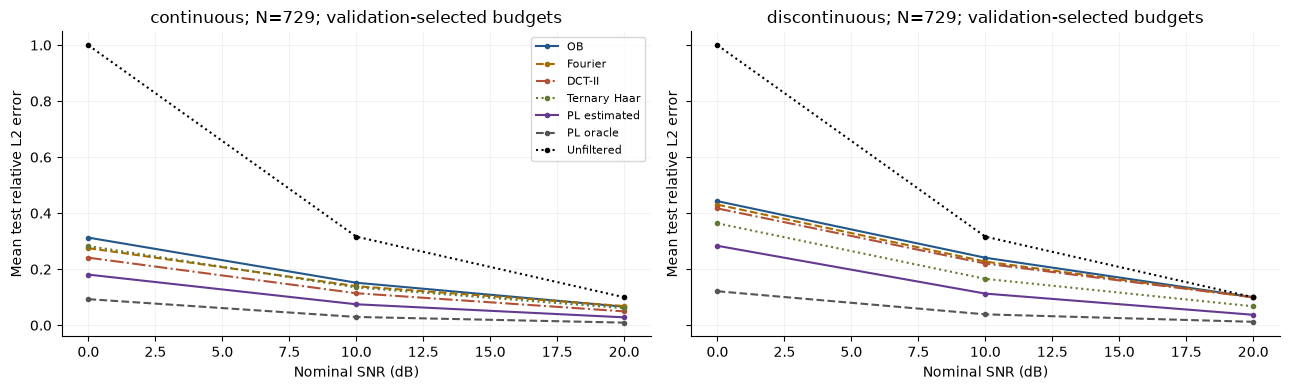

continuity,snr_db,method,relative_l2_mean,relative_l2_std,mean_bits
continuous,0,OB,0.31276,0.10642,168
continuous,0,Fourier,0.2752,0.092714,168
continuous,0,DCT-II,0.24119,0.087832,168
continuous,0,Ternary Haar,0.28254,0.10671,168
continuous,0,PL estimated,0.1807,0.077813,358
continuous,0,PL oracle,0.093094,0.042066,299.2
continuous,0,Unfiltered,0.99923,0.026371,23328
continuous,10,OB,0.15181,0.048894,672
continuous,10,Fourier,0.1394,0.033675,672
continuous,10,DCT-II,0.11435,0.061104,336


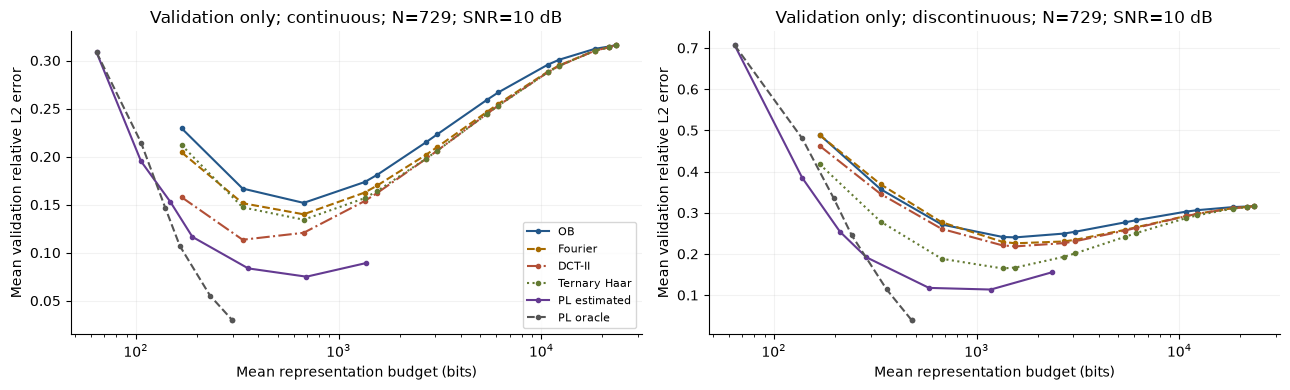

In [7]:
NOISE_SUMMARY=[]
for n,continuity,snr,method in itertools.product(CONFIG['sizes'],CONFIG['continuities'],CONFIG['noise_snr_db'],ALL_METHODS+['Unfiltered']):
    source=NOISE_BASELINE if method=='Unfiltered' else TEST_NOISE
    rows=[r for r in source if r['n']==n and r['continuity']==continuity and r['snr_db']==snr and r['method']==method]
    mean,sd=pooled(rows);boundary,bsd=pooled(rows,'boundary_rmse')
    NOISE_SUMMARY.append({'n':n,'continuity':continuity,'snr_db':snr,'method':method,'relative_l2_mean':mean,'relative_l2_std':sd,
                          'boundary_rmse_mean':boundary,'boundary_rmse_std':bsd,'mean_bits':float(np.mean([r['storage_bits'] for r in rows])),
                          'mean_paired_improvement':0. if method=='Unfiltered' else float(np.mean([r['paired_improvement_mean'] for r in rows]))})
save_csv('noise_test_summary.csv',NOISE_SUMMARY)
fig,axes=plt.subplots(1,2,figsize=(13,4),sharey=True)
for ax,continuity in zip(axes,CONFIG['continuities']):
    for method in ALL_METHODS+['Unfiltered']:
        rows=[r for r in NOISE_SUMMARY if r['n']==729 and r['continuity']==continuity and r['method']==method]
        ax.plot([r['snr_db'] for r in rows],[r['relative_l2_mean'] for r in rows],label=method,
                color=COLORS.get(method,'black'),ls=STYLES.get(method,':'),marker='.')
    ax.set(title=f'{continuity}; N=729; validation-selected budgets',xlabel='Nominal SNR (dB)',ylabel='Mean test relative L2 error')
axes[0].legend(fontsize=8);fig.tight_layout();figure(fig,'noise_frozen_test')
table([r for r in NOISE_SUMMARY if r['n']==729],['continuity','snr_db','method','relative_l2_mean','relative_l2_std','mean_bits'],limit=42)

fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,continuity in zip(axes,CONFIG['continuities']):
    for method in ALL_METHODS:
        rows=[r for r in VALIDATION_NOISE if r['n']==729 and r['continuity']==continuity and r['snr_db']==10 and r['method']==method]
        candidates=sorted(set(r['candidate'] for r in rows));xx=[];yy=[]
        for k in candidates:
            group=[r for r in rows if r['candidate']==k];xx.append(np.mean([r['storage_bits'] for r in group]));yy.append(pooled(group)[0])
        order=np.argsort(xx);ax.semilogx(np.array(xx)[order],np.array(yy)[order],label=method,color=COLORS[method],ls=STYLES[method],marker='.')
    ax.set(title=f'Validation only; {continuity}; N=729; SNR=10 dB',xlabel='Mean representation budget (bits)',ylabel='Mean validation relative L2 error')
axes[0].legend(fontsize=8);fig.tight_layout();figure(fig,'validation_budget_curves')


## 8. OB implementation: storage, loading and computation
This section does not rank mathematical bases. Equal-valued float32 and int8 SafeTensor pairs are temporarily created for each size. Measurements separate file bytes, load latency, process RSS change, active MLX memory after loading, and memory after explicit float32 casts. Each measurement runs in a separate process, with three repeats. RSS depends on file mapping and allocation, especially for small matrices.

Standard `OBMatrix` forward/inverse calls run on GPU, batch=64. Timing stops after `mx.eval()`. A common warm-up lasts at least 0.15 s, followed by extra warm-up calls; timed operations are interleaved to reduce order effects. OS file caches are not cleared. Peak MLX allocator usage is separate from system peak RSS. Computation remains float32 even with int8 files. Temporary copies are deleted and source assets are unchanged.

The combined matrix alphabet has at most four values, allowing a theoretical two bits per element. No packed kernel is implemented. Replacing multiplication by signs/addition/doubling still requires O(N²) dense accesses. Ternary dot products admit complex-character factors by digit: m stages of O(N), potentially O(N log₃N) plus real pair conversion. No such algorithm, integer implementation or speedup is measured here.

n,storage_dtype,file_bytes,matrix_array_bytes,load_rss_delta_bytes,explicit_cast_active_delta_bytes,runtime_peak_mlx_bytes,forward_ms,inverse_ms,pair_ms
81,float32,52655,52488,6.0621e+05,0,2.2938e+05,0.11979,0.10938,0.12579
81,int8,13285,13122,5.7344e+05,65536,2.7527e+05,0.12133,0.11462,0.133
243,float32,4.7257e+05,4.7239e+05,1.0322e+06,0,1.2124e+06,0.11983,0.11729,0.13383
243,int8,1.1827e+05,1.181e+05,6.7174e+05,4.9152e+05,1.5893e+06,0.12417,0.11921,0.137
729,float32,4.2517e+06,4.2515e+06,4.8005e+06,0,6.3734e+06,0.12838,0.12229,0.15179
729,int8,1.0631e+06,1.0629e+06,1.6384e+06,4.2598e+06,9.5846e+06,0.1425,0.13733,0.17475
2187,float32,3.8264e+07,3.8264e+07,3.8814e+07,0,4.4532e+07,0.23575,0.22729,0.31571
2187,int8,9.5661e+06,9.5659e+06,1.0109e+07,3.8273e+07,7.3236e+07,0.31196,0.3055,0.45963


n,float32_pair_payload_bytes,int8_pair_payload_bytes,two_bit_pair_payload_bytes
81,52488,13122,3282
243,472392,118098,29526
729,4251528,1062882,265722
2187,38263752,9565938,2391486


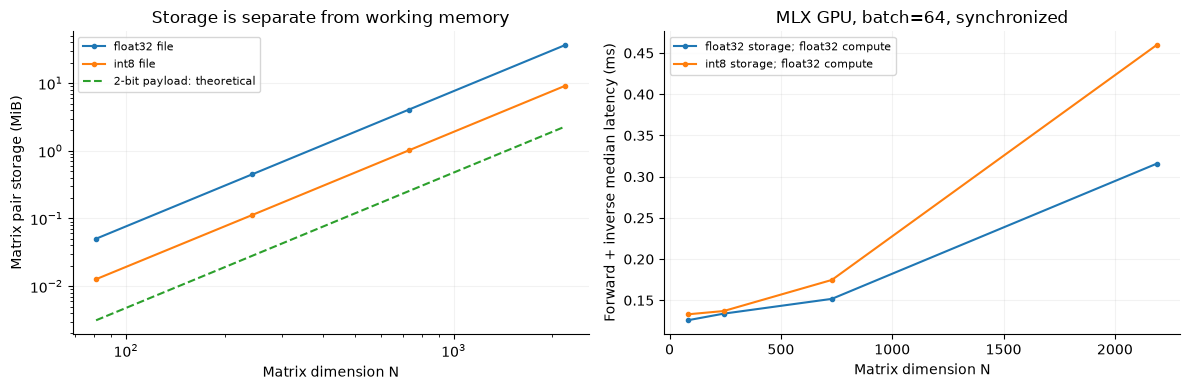

In [8]:
MEMORY_WORKER = r"""
import gc,json,sys,time
from pathlib import Path
import numpy as np
import mlx.core as mx
import psutil
from obf.core import OBMatrix
folder=sys.argv[1]
n,batch,warm,repeats=map(int,sys.argv[2:6]);warm_seconds=float(sys.argv[6])
process=psutil.Process()
mx.clear_cache();gc.collect()
rss0=process.memory_info().rss;active0=mx.get_active_memory()
start=time.perf_counter();model=OBMatrix(n,matrices_dir=folder);mx.eval(*model._matrix.values())
load_ms=(time.perf_counter()-start)*1000
rss_loaded=process.memory_info().rss;active_loaded=mx.get_active_memory()
array_bytes=sum(v.nbytes for v in model._matrix.values())
cast={k:v.astype(mx.float32) for k,v in model._matrix.items()};mx.eval(*cast.values())
rss_cast=process.memory_info().rss;active_cast=mx.get_active_memory()
del cast;gc.collect();mx.clear_cache()
x=mx.array(np.random.default_rng(42).normal(size=(batch,n)).astype(np.float32));c=model(x);mx.eval(x,c)
operations={'forward':lambda:model(x),'inverse':lambda:model.inverse(c),'pair':lambda:model.inverse(model(x))}
latencies={}
mx.reset_peak_memory()
warm_end=time.perf_counter()+warm_seconds
while time.perf_counter()<warm_end:
 for fn in operations.values():out=fn();mx.eval(out)
for _ in range(warm):
 for fn in operations.values():out=fn();mx.eval(out)
times={name:[] for name in operations};names=list(operations)
for repeat in range(repeats):
 for name in names[repeat%3:]+names[:repeat%3]:
  start=time.perf_counter();out=operations[name]();mx.eval(out);times[name].append((time.perf_counter()-start)*1000)
for name,values in times.items():
 latencies[name+'_ms']=float(np.median(values))
 latencies[name+'_iqr_ms']=float(np.quantile(values,.75)-np.quantile(values,.25))
print(json.dumps({'load_ms':load_ms,'matrix_array_bytes':array_bytes,
 'load_rss_delta_bytes':rss_loaded-rss0,'load_active_delta_bytes':active_loaded-active0,
 'rss_cast_minus_baseline_bytes':rss_cast-rss0,'explicit_cast_active_delta_bytes':active_cast-active_loaded,
 'runtime_peak_mlx_bytes':mx.get_peak_memory(),'runtime_active_mlx_bytes':mx.get_active_memory(),**latencies}))
"""
STORAGE_RAW=[];STORAGE_SUMMARY=[];THEORY=[]
for n in CONFIG['sizes']:
    saved=mx.load(str(asset_dir(n)/f'ob_mx_{n}.safetensors'))
    original_bytes=(asset_dir(n)/f'ob_mx_{n}.safetensors').stat().st_size
    with tempfile.TemporaryDirectory(prefix='ob-storage-') as temp:
        for label,dtype in [('float32',mx.float32),('int8',mx.int8)]:
            destination=Path(temp)/label;destination.mkdir()
            path=destination/f'ob_mx_{n}.safetensors'
            arrays={k:v.astype(dtype) for k,v in saved.items()};mx.eval(*arrays.values())
            mx.save_safetensors(str(path),arrays)
            loaded=mx.load(str(path));assert all(np.array_equal(np.asarray(loaded[k]),np.asarray(saved[k])) for k in saved)
            for repeat in range(CONFIG['storage_process_repeats']):
                command=[sys.executable,'-c',MEMORY_WORKER,str(destination),str(n),str(CONFIG['timing_batch']),str(CONFIG['timing_warmup']),str(CONFIG['timing_repeats']),str(CONFIG['timing_min_warmup_seconds'])]
                result=subprocess.run(command,cwd=ROOT,capture_output=True,text=True,check=True)
                stats=json.loads(result.stdout.strip().splitlines()[-1])
                STORAGE_RAW.append({'n':n,'storage_dtype':label,'repeat':repeat,'file_bytes':path.stat().st_size,
                                    'source_file_bytes':original_bytes,**stats})
            group=[r for r in STORAGE_RAW if r['n']==n and r['storage_dtype']==label]
            row={'n':n,'storage_dtype':label}
            for key in group[0]:
                if key not in ['n','storage_dtype','repeat']:row[key]=float(np.median([r[key] for r in group]))
            STORAGE_SUMMARY.append(row)
    f=np.asarray(saved['forward']);b=np.asarray(saved['inverse'])
    alphabet=np.unique(np.r_[np.unique(f),np.unique(b)])
    assert len(alphabet)<=4
    THEORY.append({'n':n,'float32_pair_payload_bytes':8*n*n,'int8_pair_payload_bytes':2*n*n,
                   'two_bit_pair_payload_bytes':2*math.ceil(n*n/4),'alphabet':','.join(map(str,alphabet)),
                   'forward_negative_two_count':int(np.sum(f==-2)),'inverse_zero_count':int(np.sum(b==0)),
                   'dense_scalar_products_per_forward_vector':n*n,'ternary_stages':round(math.log(n,3))})
    progress('storage_measurements',n)
save_csv('storage_process_measurements.csv',STORAGE_RAW);save_csv('storage_summary.csv',STORAGE_SUMMARY);save_csv('storage_theory.csv',THEORY)
table(STORAGE_SUMMARY,['n','storage_dtype','file_bytes','matrix_array_bytes','load_rss_delta_bytes','explicit_cast_active_delta_bytes','runtime_peak_mlx_bytes','forward_ms','inverse_ms','pair_ms'],limit=10)
table(THEORY,['n','float32_pair_payload_bytes','int8_pair_payload_bytes','two_bit_pair_payload_bytes'])
fig,axes=plt.subplots(1,2,figsize=(12,4))
for label in ['float32','int8']:
    rows=[r for r in STORAGE_SUMMARY if r['storage_dtype']==label]
    axes[0].loglog([r['n'] for r in rows],[r['file_bytes']/2**20 for r in rows],marker='.',label=f'{label} file')
    axes[1].plot([r['n'] for r in rows],[r['pair_ms'] for r in rows],marker='.',label=f'{label} storage; float32 compute')
axes[0].loglog([r['n'] for r in THEORY],[r['two_bit_pair_payload_bytes']/2**20 for r in THEORY],ls='--',label='2-bit payload: theoretical')
axes[0].set(xlabel='Matrix dimension N',ylabel='Matrix pair storage (MiB)',title='Storage is separate from working memory')
axes[1].set(xlabel='Matrix dimension N',ylabel='Forward + inverse median latency (ms)',title=f'MLX GPU, batch={CONFIG["timing_batch"]}, synchronized')
for ax in axes:ax.legend(fontsize=8)
fig.tight_layout();figure(fig,'storage_and_runtime')


## 9. Summary results
The slices below equally weight all segment counts, profiles and boundary modes. CSV files contain every configuration. Practical estimated fitting is separate from oracle; low oracle error reflects known knots, not successful boundary detection.

n,continuity,method,relative_l2_mean,relative_l2_std,boundary_rmse_mean,boundary_rmse_std,mean_bits,mean_float_params,mean_index_params
729,continuous,OB,0.0069073,0.011929,0.015483,0.028725,6132,146,146
729,continuous,Fourier,0.023202,0.016437,0.012131,0.017783,6132,146,146
729,continuous,DCT-II,0.002144,0.004578,0.00668,0.015636,6132,146,146
729,continuous,Ternary Haar,0.0082431,0.010198,0.008675,0.010903,6132,146,146
729,continuous,PL estimated,0.00028424,0.0009962,0.0012124,0.0043847,1366,33,31
729,continuous,PL oracle,3.9845e-08,8.9484e-09,3.7832e-08,2.025e-08,299.2,7.6,5.6
729,discontinuous,OB,0.076444,0.071072,0.33593,0.36565,6132,146,146
729,discontinuous,Fourier,0.084189,0.038146,0.3923,0.24366,6132,146,146
729,discontinuous,DCT-II,0.076638,0.040595,0.40001,0.24565,6132,146,146
729,discontinuous,Ternary Haar,0.010843,0.0091177,0.0099419,0.0092982,6132,146,146


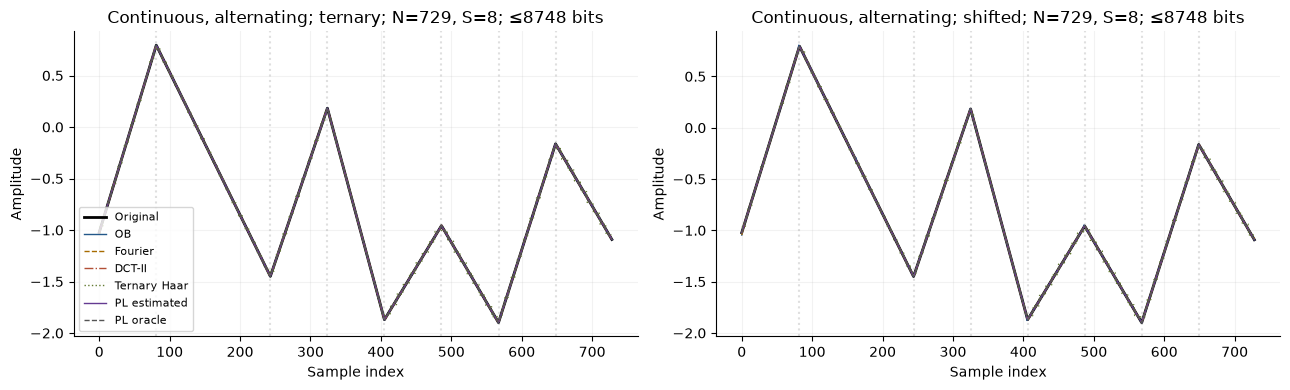

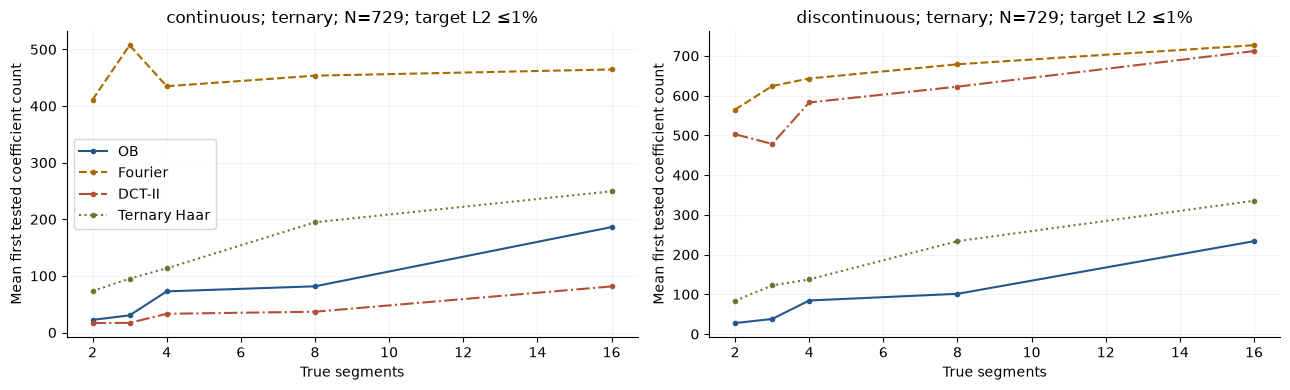

In [9]:
CLEAN_SUMMARY=[]
for n,continuity,method in itertools.product(CONFIG['sizes'],CONFIG['continuities'],ALL_METHODS):
    rows=[r for r in FIXED if r['n']==n and r['continuity']==continuity and r['method']==method]
    mean,sd=pooled(rows);boundary,bsd=pooled(rows,'boundary_rmse')
    CLEAN_SUMMARY.append({'n':n,'continuity':continuity,'method':method,'relative_l2_mean':mean,'relative_l2_std':sd,
                          'boundary_rmse_mean':boundary,'boundary_rmse_std':bsd,'mean_bits':float(np.mean([r['storage_bits'] for r in rows])),
                          'mean_float_params':float(np.mean([r['float_params'] for r in rows])),
                          'mean_index_params':float(np.mean([r['index_params'] for r in rows]))})
save_csv('clean_summary.csv',CLEAN_SUMMARY)
table([r for r in CLEAN_SUMMARY if r['n']==729],limit=15)

fig,axes=plt.subplots(1,2,figsize=(13,4),sharex=True)
for ax,alignment in zip(axes,['ternary','shifted']):
    cfg=(8,alignment,'continuous','alternating');x,knots,_,_=generate_signals(729,*cfg,'test')
    ax.plot(x[0],color='black',lw=2,label='Original')
    limit=CONFIG['fixed_bits_per_sample']*729
    counts={m:next(r['candidate'] for r in FIXED if r['n']==729 and r['segments']==8 and r['alignment']==alignment and r['continuity']=='continuous' and r['profile']=='alternating' and r['method']==m) for m in ALL_METHODS}
    for method,candidate,actual,predicted,values in evaluate_observation(x,x,knots,'continuous',MODELS[729],counts):
        ax.plot(predicted[0],label=method,color=COLORS[method],ls=STYLES[method],lw=1)
    for cut in knots[0,1:-1]:ax.axvline(cut,color='gray',ls=':',alpha=.25)
    ax.set(title=f'Continuous, alternating; {alignment}; N=729, S=8; ≤{limit} bits',xlabel='Sample index',ylabel='Amplitude')
axes[0].legend(fontsize=8);fig.tight_layout();figure(fig,'piecewise_examples')

GROWTH_SUMMARY=[]
for n,continuity,alignment,s,method in itertools.product(CONFIG['sizes'],CONFIG['continuities'],CONFIG['alignments'],CONFIG['segments'],ALL_METHODS):
    rows=[r for r in NEEDED if r['n']==n and r['continuity']==continuity and r['alignment']==alignment and r['segments']==s and r['method']==method and r['target_relative_error']==.01]
    GROWTH_SUMMARY.append({'n':n,'continuity':continuity,'alignment':alignment,'segments':s,'method':method,
                           'mean_first_tested_bits_1pct':float(np.nanmean([r['first_grid_bits_mean_reached'] for r in rows])),
                           'mean_first_tested_components_1pct':float(np.nanmean([r['first_grid_components_mean_reached'] for r in rows])),
                           'mean_reached_fraction':float(np.mean([r['reached_fraction'] for r in rows]))})
save_csv('growth_summary.csv',GROWTH_SUMMARY)
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,continuity in zip(axes,CONFIG['continuities']):
    for method in BASIS_METHODS:
        rows=[r for r in GROWTH_SUMMARY if r['n']==729 and r['continuity']==continuity and r['alignment']=='ternary' and r['method']==method]
        ax.plot([r['segments'] for r in rows],[r['mean_first_tested_components_1pct'] for r in rows],label=method,color=COLORS[method],ls=STYLES[method],marker='.')
    ax.set(title=f'{continuity}; ternary; N=729; target L2 ≤1%',xlabel='True segments',ylabel='Mean first tested coefficient count')
axes[0].legend();fig.tight_layout();figure(fig,'coefficient_count_growth')

(OUT/'run_metadata.json').write_text(json.dumps({'config':CONFIG,'environment':ENV,'source_hashes':SOURCE_HASHES,
    'configurations_per_dimension':len(CONFIGURATIONS),'test_signals_total':len(CONFIGURATIONS)*len(CONFIG['sizes'])*CONFIG['test_samples'],
    'validation_signals_total':len(CONFIGURATIONS)*len(CONFIG['sizes'])*CONFIG['validation_samples'],
    'selection_policy':'One candidate per dimension, SNR, known continuity and method; validation only; no test alignment/segment conditioning.',
    'affine_threshold':CONFIG['affine_relative_threshold'],'elapsed_statistical_and_reporting_seconds':time.perf_counter()-START},indent=2))
progress('complete')


## 10. Conclusions and limitations
Executed configuration: seed=42, N=81/243/729/2187, 90 configurations per size, 64 validation and 64 test signals each (23,040 in each split). After configuration changes, check numbers against regenerated CSVs and tables.

1. **Linear-function property.** Nonconstant affine signals have `log₃(N)+1` active coefficients when their mean is nonzero, centered linear trends have `log₃(N)`, and nonzero constants have one. Active indices are 0 and `2·3ʳ`. The formula follows from ternary digits and is checked with exact int64 products and float64 calculations at all seven dimensions; it is not merely a numerical hypothesis.
2. **Piecewise-linear complexity.** Trend compactness partly extends, but no law depending only on segment count is established. At N=729, aligned continuous signals need mean first-tested K of about 22 for two segments, rising to 186 for 16 at relative L2 ≤1%; discontinuous signals rise from about 28 to 234. These are grid upper estimates under the selected mask, not exact minimum K. Slope profiles and boundary-grid depth matter.
3. **Boundary placement.** At N=729, K=146 (6132 bits with indices), mean OB error on aligned discontinuous signals is 0.00578, increasing to 0.11184 after shifting the same boundaries by 1–5 samples. Continuous errors are 0.00226 and 0.00452. Boundary errors are saved separately. This tests a common internal-knot shift, not independent knot jitter.
4. **Representation comparisons.** OB beats Haar (0.01052), DCT (0.07257) and Fourier (0.08120) on aligned discontinuous data in this slice. After shifts, Haar is more robust (0.01198). DCT is better on average for continuous data. Direct PL fitting generally achieves lower error with fewer bits for this known family, even accounting for boundaries. Oracle is nearly exact with all true knots; predetermined oracle subsets at insufficient budgets are not optimal and can lose to estimated fitting.
5. **Denoising with frozen budgets.** At N=729 and Gaussian SNR=10 dB, unfiltered error is about 0.316. Continuous errors are OB 0.152, DCT 0.114, Haar 0.135, estimated PL 0.0749; discontinuous errors are 0.241, 0.220, 0.166 and 0.113. Validation alone selects budgets, pooling profiles and alignments; methods use different budgets. For discontinuous mixed data at 20 dB, validation selects full OB K=N. No consistent OB denoising advantage is found in this protocol. Specific known subfamilies might require another validation design.
6. **Fixed-transform utility.** A narrow OB advantage over the required fixed bases occurs for ordered, ternary-aligned discontinuous piecewise-linear signals. No advantage over specialized fitting is established for arbitrary boundaries or direct piecewise-linear coding/denoising. A useful representation for suitable structure remains a hypothesis; trainable activations and neural architectures were not evaluated.
7. **Implementation cost.** At N=2187, float32 matrix-pair storage is 36.49 MiB, int8 is 9.12 MiB and theoretical two-bit payload is 2.28 MiB before headers. The initial M4 Max GPU run (batch=64) measured forward+inverse medians of about 0.314 ms for float32 storage and 0.456 ms for int8, with peak MLX allocations about 42.5 and 69.8 MiB. These historical timing values are descriptive; regenerated timing tables are authoritative for the current run. Int8 reduces stored/loaded weights but temporary float32 casts raise the working peak in current code. RSS is measured separately and is not added to MLX memory. Sign/doubling arithmetic still leaves dense O(N²) traversal. Ternary factorization suggests O(N log₃N) staged operations; this is theoretical, not an implemented or measured fast kernel.

**Limitations.** One seed, synthetic functions and known continuity types. Sizes use different realizations, so comparisons across N are unpaired. Aligned/shifted samples are paired; reported standard deviations describe observations, not independent-group confidence intervals. Estimated fitting is heuristic; boundary refinement can make error nonmonotonic in knot count. K grids are discrete and bit budgets omit headers and entropy coding. Continuity identification was not tested. Quality conclusions apply to this data family, not arbitrary signals. Memory and latency concern this backend and machine; packed and fast factorized implementations do not exist here.